## Dataset Preprocessing, Tokenizer & Custom VAE

In [ ]:
%pip install -U datasets huggingface_hub pillow pandas matplotlib tqdm
%pip install -U torch torchvision
%pip install torchinfo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# Imports, Seeds & Directory Setup
from pathlib import Path
import os, re, json, random, time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchinfo import summary

# Set seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Define project directory structure
PROJECT_DIR = Path(r"C:\DNN\DNN_Project")
RAW_DIR = PROJECT_DIR / "dataset" / "raw"
DATA_DIR = PROJECT_DIR / "dataset" / "flickr8k"
MODEL_DIR = PROJECT_DIR / "models"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
LATENT_DIR = PROJECT_DIR / "latents"
TOKENIZER_DIR = PROJECT_DIR / "tokenizer"
RESULTS_DIR = PROJECT_DIR / "results"

for folder in [RAW_DIR, DATA_DIR, MODEL_DIR, CHECKPOINT_DIR, LATENT_DIR, TOKENIZER_DIR, RESULTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Hardware detection
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")

# Image and VAE configuration
IMAGE_SIZE = 64
LATENT_CHANNELS = 4

# Training configuration
BATCH_SIZE = 16
NUM_WORKERS = 0  
EPOCHS = 100
PATIENCE = 7
LEARNING_RATE = 1e-4
BETA_KL = 1e-4

# Tokenizer configuration
MAX_VOCAB_SIZE = 10_000
MIN_WORD_FREQ = 1
MAX_TEXT_LENGTH = 40

print("\nConfiguration loaded successfully.")
print(f"Image size: {IMAGE_SIZE}x{IMAGE_SIZE}")
print(f"Latent shape per image: {LATENT_CHANNELS}x16x16")
print(f"Maximum epochs: {EPOCHS} (Early stopping patience: {PATIENCE})")
print(f"Tokenizer max vocab: {MAX_VOCAB_SIZE}, min freq: {MIN_WORD_FREQ}, max length: {MAX_TEXT_LENGTH}")


PyTorch: 2.14.1+cu132
Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
VRAM: 4.00 GB

Configuration loaded successfully.
Image size: 64x64
Latent shape per image: 4x16x16
Maximum epochs: 100 (Early stopping patience: 7)
Tokenizer max vocab: 10000, min freq: 1, max length: 40


### Download Raw Dataset into `dataset/raw/`

In [4]:
from datasets import load_dataset

print(f"Downloading dataset to: {RAW_DIR}")
hf_dataset = load_dataset(
    "intro/flickr8k",
    cache_dir=str(RAW_DIR)
)
print("Download complete!")
print(hf_dataset)

Resolving data files:   0%|          | 0/6001 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/1001 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/1001 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/6001 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/1001 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/1001 [00:00<?, ?it/s]

Download complete!
DatasetDict({
    train: Dataset({
        features: ['image', 'split', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4'],
        num_rows: 6000
    })
    dev: Dataset({
        features: ['image', 'split', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['image', 'split', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4'],
        num_rows: 1000
    })
})


Dataset splits: ['train', 'dev', 'test']

Original images in train: 6000
Image 1: size=(375, 500), mode=RGB
Image 2: size=(500, 375), mode=RGB
Image 3: size=(500, 400), mode=RGB
Image 4: size=(500, 410), mode=RGB
Image 5: size=(500, 461), mode=RGB

train split
Total images: 6000
Number of unique image sizes: 550
Most common original dimensions:
  500 × 333: 1131 images
  500 × 375: 965 images
  333 × 500: 485 images
  375 × 500: 325 images
  500 × 334: 244 images
  500 × 332: 180 images
  334 × 500: 123 images
  500 × 335: 89 images
  500 × 400: 86 images
  332 × 500: 82 images

dev split
Total images: 1000
Number of unique image sizes: 242
Most common original dimensions:
  500 × 333: 184 images
  500 × 375: 159 images
  333 × 500: 79 images
  375 × 500: 50 images
  500 × 334: 46 images
  500 × 332: 36 images
  334 × 500: 22 images
  400 × 500: 14 images
  500 × 400: 13 images
  500 × 335: 12 images

test split
Total images: 1000
Number of unique image sizes: 234
Most common original 

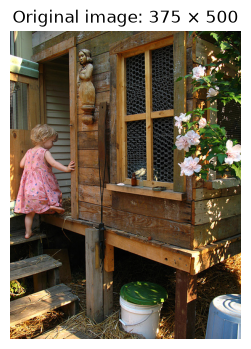

In [ ]:
from collections import Counter
from PIL import Image
import matplotlib.pyplot as plt

# Check the available dataset splits
print("Dataset splits:", list(hf_dataset.keys()))

# Inspect a few original images before preprocessing
split_name = "train"
sample_split = hf_dataset[split_name]

print(f"\nOriginal images in {split_name}: {len(sample_split)}")

for i in range(min(5, len(sample_split))):
    image = sample_split[i]["image"]

    print(
        f"Image {i + 1}: "
        f"size={image.size}, "
        f"mode={image.mode}"
    )

# Count original image dimensions across each split
for split_name, dataset_split in hf_dataset.items():
    sizes = Counter()

    for row in dataset_split:
        image = row["image"]
        sizes[image.size] += 1

    print(f"\n{split_name} split")
    print(f"Total images: {len(dataset_split)}")
    print(f"Number of unique image sizes: {len(sizes)}")

    print("Most common original dimensions:")
    for size, count in sizes.most_common(10):
        print(f"  {size[0]} × {size[1]}: {count} images")

# Visualize an original image and its dimensions
image = sample_split[0]["image"]

plt.figure(figsize=(6, 4))
plt.imshow(image)
plt.title(f"Original image: {image.width} × {image.height}")
plt.axis("off")
plt.show()

### Preprocess & Center-Crop to 64x64 Images

In [4]:
# Cell 4: Preprocessing and Exporting 64x64 Images

def extract_image(item):
    for key in ["image", "img", "picture", "jpg"]:
        if key not in item or item[key] is None:
            continue

        val = item[key]

        if isinstance(val, Image.Image):
            return val.convert("RGB")

        if isinstance(val, dict) and val.get("bytes") is not None:
            import io
            with Image.open(io.BytesIO(val["bytes"])) as img:
                return img.convert("RGB")

        if isinstance(val, str) and os.path.exists(val):
            with Image.open(val) as img:
                return img.convert("RGB")

    raise KeyError(
        f"Cannot find an image in columns: {list(item.keys())}"
    )


def extract_captions(item):
    caption_keys = sorted(
        [
            k for k in item
            if re.fullmatch(r"caption[_-]?\d+", k, re.IGNORECASE)
        ],
        key=lambda k: int(re.search(r"\d+", k).group())
    )

    captions = [
        str(item[k]).strip()
        for k in caption_keys
        if item[k] is not None and str(item[k]).strip()
    ]

    if captions:
        return captions

    for key in ["captions", "caption", "text", "sentence"]:
        if key not in item or item[key] is None:
            continue

        val = item[key]

        if isinstance(val, str) and val.strip():
            return [val.strip()]

        if isinstance(val, (list, tuple)):
            result = [
                str(c).strip()
                for c in val
                if c is not None and str(c).strip()
            ]
            if result:
                return result

    raise KeyError(
        f"Cannot find captions in columns: {list(item.keys())}"
    )


def get_split_mapping(ds):
    mapping = {}

    if "train" in ds:
        mapping["train"] = "train"

    if "validation" in ds:
        mapping["validation"] = "val"
    elif "dev" in ds:
        mapping["dev"] = "val"

    if "test" in ds:
        mapping["test"] = "test"

    if not mapping:
        raise ValueError("No recognized dataset splits were found.")

    return mapping


split_mapping = get_split_mapping(hf_dataset)

print("Split mapping:", split_mapping)

# Export processed images and captions
for source_split, output_split in split_mapping.items():
    split_data = hf_dataset[source_split]

    output_dir = DATA_DIR / output_split
    image_dir = output_dir / "images"

    image_dir.mkdir(parents=True, exist_ok=True)

    rows = []
    print(
        f"\nExporting {source_split} -> {output_split} "
        f"({len(split_data)} images)..."
    )

    for index, item in enumerate(tqdm(split_data)):
        # Extract and validate both before writing the image
        raw_img = extract_image(item)
        captions = extract_captions(item)

        # Center-crop and resize without distorting aspect ratio
        image = ImageOps.fit(
            raw_img,
            (IMAGE_SIZE, IMAGE_SIZE),
            method=Image.Resampling.LANCZOS
        )

        image_name = f"{output_split}_{index:05d}.jpg"
        image_path = image_dir / image_name

        image.save(image_path, format="JPEG", quality=95)

        rows.append({
            "image": image_name,
            "image_id": f"{output_split}_{index:05d}",
            "captions": json.dumps(
                captions, ensure_ascii=False
            ),
            "caption_count": len(captions),
        })

    output_csv = output_dir / "captions.csv"
    pd.DataFrame(rows).to_csv(
        output_csv, index=False, encoding="utf-8"
    )

    print(f"Saved {output_csv} ({len(rows)} rows)")

print(f"\nPreprocessing complete: {DATA_DIR}")

Split mapping: {'train': 'train', 'dev': 'val', 'test': 'test'}

Exporting train -> train (6000 images)...


  0%|          | 0/6000 [00:00<?, ?it/s]

Saved C:\DNN\DNN_Project\dataset\flickr8k\train\captions.csv (6000 rows)

Exporting dev -> val (1000 images)...


  0%|          | 0/1000 [00:00<?, ?it/s]

Saved C:\DNN\DNN_Project\dataset\flickr8k\val\captions.csv (1000 rows)

Exporting test -> test (1000 images)...


  0%|          | 0/1000 [00:00<?, ?it/s]

Saved C:\DNN\DNN_Project\dataset\flickr8k\test\captions.csv (1000 rows)

Preprocessing complete: C:\DNN\DNN_Project\dataset\flickr8k


### Dataset & Image Verification Check
Verify that all exported images and captions across train, val, and test splits are valid, non-empty, and match dimensions (64, 64) in RGB format.


In [27]:
# Dataset & Image Verification Check
expected_counts = {
    "train": 6000,
    "val": 1000,
    "test": 1000,
}

for split, expected in expected_counts.items():
    split_dir = DATA_DIR / split
    image_dir = split_dir / "images"
    csv_path = split_dir / "captions.csv"

    df = pd.read_csv(csv_path)
    assert len(df) == expected, f"{split}: expected {expected} rows, got {len(df)}"
    assert df["image"].is_unique, f"{split}: duplicate filenames"

    errors = []
    for filename in df["image"]:
        image_path = image_dir / filename
        if not image_path.exists():
            errors.append(f"Missing: {filename}")
            continue
        try:
            with Image.open(image_path) as img:
                if img.size != (IMAGE_SIZE, IMAGE_SIZE) or img.mode != "RGB":
                    errors.append(f"{filename}: size={img.size}, mode={img.mode}")
        except Exception as exc:
            errors.append(f"{filename}: {exc}")

    # Verify caption JSON and count column
    for _, row in df.iterrows():
        captions = json.loads(row["captions"])
        if len(captions) != row["caption_count"] or not captions:
            img_name = row["image"]
            errors.append(f"Invalid captions: {img_name}")

    print(f"{split}: {len(df)} rows, {len(errors)} errors")
    if errors:
        print("\n".join(errors[:10]))
        raise ValueError(f"Dataset verification failed for {split}")

print("\nAll exported splits passed verification.")


train: 6000 rows, 0 errors
val: 1000 rows, 0 errors
test: 1000 rows, 0 errors

All exported splits passed verification.


### Inspect Processed Samples
Visualize sample 64x64 images and paired captions with wrapped titles.


,image,image_id,captions,caption_count
0,train_00000.jpg,train_00000,"[""A child in a pink dress is climbing up a set...",5
1,train_00001.jpg,train_00001,"[""A black dog and a spotted dog are fighting"",...",5
2,train_00002.jpg,train_00002,"[""A little girl covered in paint sits in front...",5
3,train_00003.jpg,train_00003,"[""A man lays on a bench while his dog sits by ...",5
4,train_00004.jpg,train_00004,"[""A man in an orange hat starring at something...",5


Training images count: 6000
Caption count distribution: {5: 6000}


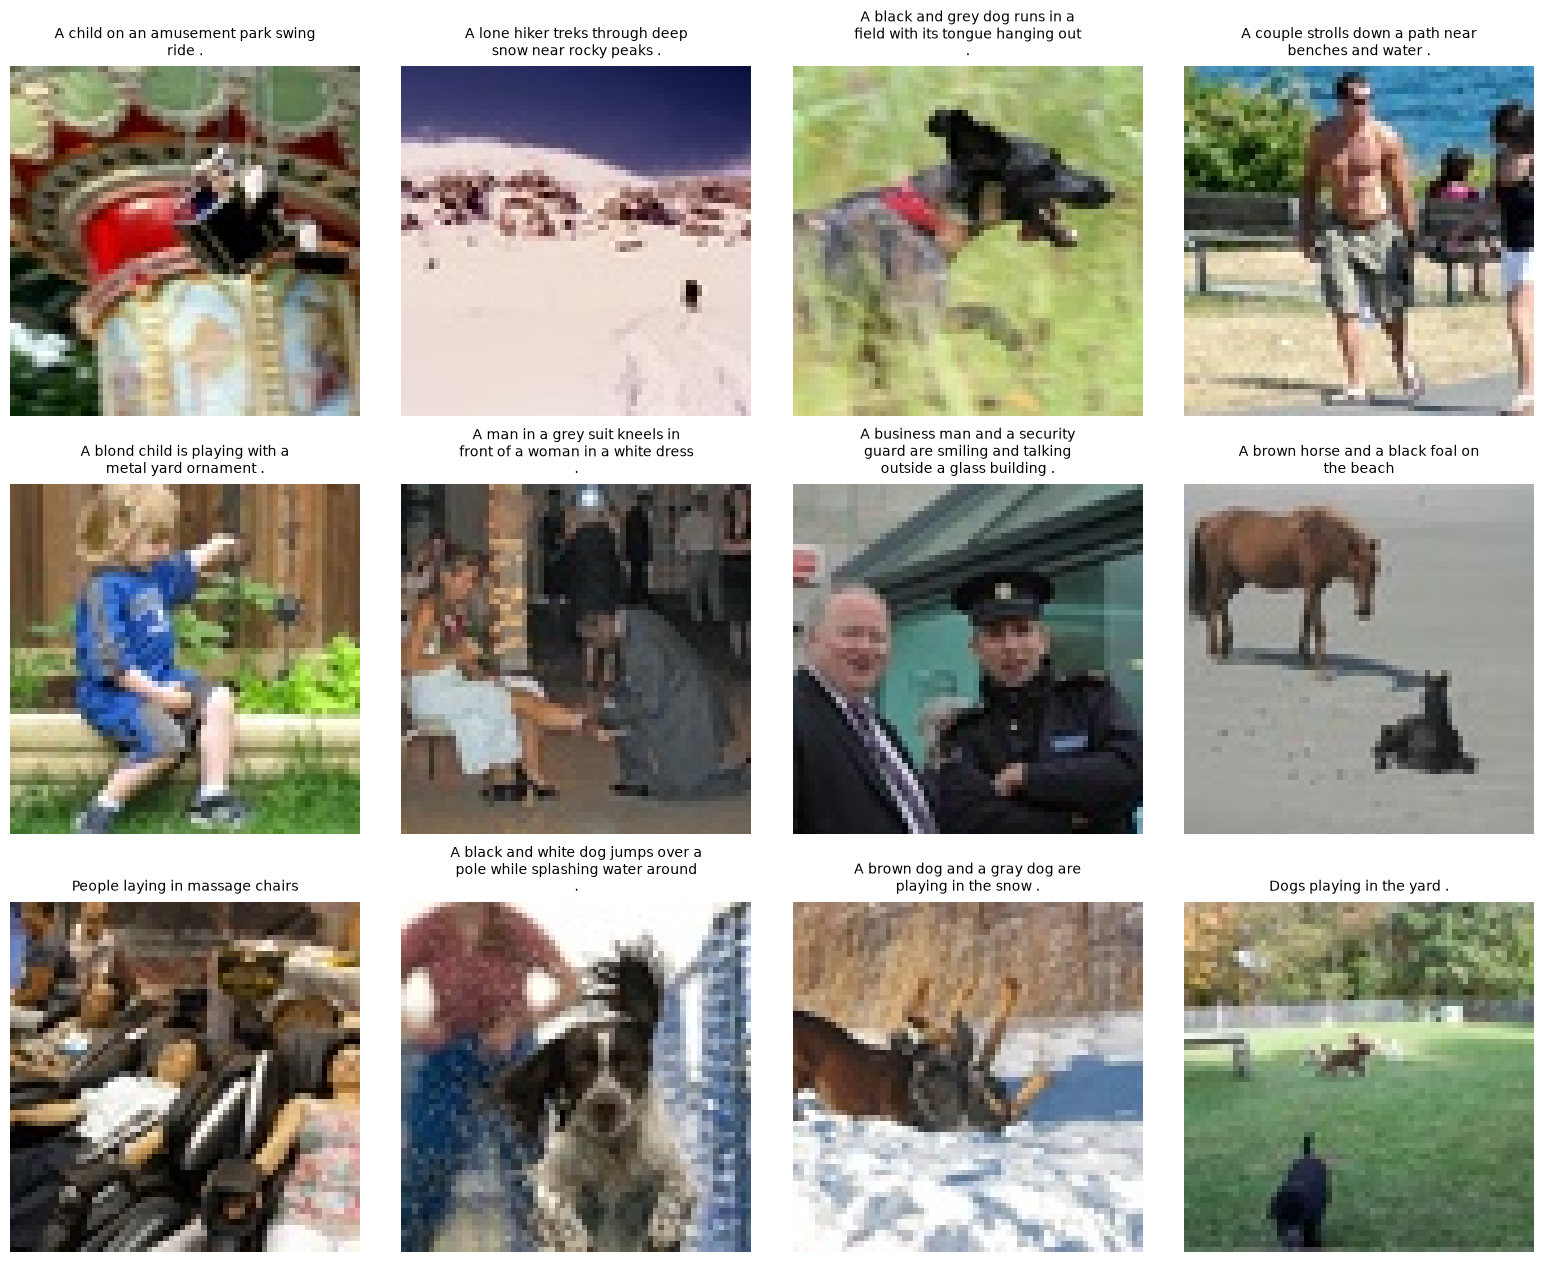

In [ ]:
# Inspect Processed Dataset 
import textwrap

train_csv = DATA_DIR / "train" / "captions.csv"
train_df = pd.read_csv(train_csv)
display(train_df.head())
print("Training images count:", len(train_df))
print("Caption count distribution:", train_df["caption_count"].value_counts().to_dict())

# Visualize 12 samples
n = min(12, len(train_df))
sample = train_df.sample(n=n, random_state=SEED)

fig, axes = plt.subplots(3, 4, figsize=(16, 13))
for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    img = Image.open(DATA_DIR / "train" / "images" / row["image"]).convert("RGB")
    caption_list = json.loads(row["captions"])
    ax.imshow(img)
    cap = caption_list[0]
    # Wrap caption text cleanly into multiple lines 
    wrapped_cap = textwrap.fill(cap, width=34)
    ax.set_title(wrapped_cap, fontsize=10, pad=8)
    ax.axis("off")

plt.tight_layout(pad=2.5)
plt.show()


### Custom Word Tokenizer & Vocabulary Builder

In [ ]:
# Tokenizer Implementation (Train Captions Only)
SPECIAL_TOKENS = ["<pad>", "<unk>", "<bos>", "<eos>"]

def tokenize_text(text):
    return re.findall(r"[a-z0-9]+(?:'[a-z]+)?", str(text).lower())

# Build vocabulary exclusively from training captions
train_csv_path = DATA_DIR / "train" / "captions.csv"
train_frame = pd.read_csv(train_csv_path)

word_counts = Counter()
for packed in train_frame["captions"]:
    caption_list = json.loads(packed) if isinstance(packed, str) else [str(packed)]
    for caption in caption_list:
        word_counts.update(tokenize_text(caption))

word_to_id = {token: i for i, token in enumerate(SPECIAL_TOKENS)}
for word, freq in word_counts.most_common():
    if freq < MIN_WORD_FREQ or len(word_to_id) >= MAX_VOCAB_SIZE:
        continue
    if word not in word_to_id:
        word_to_id[word] = len(word_to_id)

id_to_word = {idx: token for token, idx in word_to_id.items()}

PAD_ID = word_to_id["<pad>"]
UNK_ID = word_to_id["<unk>"]
BOS_ID = word_to_id["<bos>"]
EOS_ID = word_to_id["<eos>"]

def encode_caption(text, max_length=MAX_TEXT_LENGTH):
    tokens = tokenize_text(text)
    ids = [BOS_ID] + [word_to_id.get(t, UNK_ID) for t in tokens[:max_length-2]] + [EOS_ID]
    ids = ids[:max_length]
    ids += [PAD_ID] * (max_length - len(ids))
    return ids

def decode_caption(token_ids):
    words = []
    for token_id in token_ids:
        token = id_to_word.get(int(token_id), "<unk>")
        if token == "<eos>":
            break
        if token not in SPECIAL_TOKENS:
            words.append(token)
    return " ".join(words)

# Save vocabulary and configuration
TOKENIZER_DIR.mkdir(parents=True, exist_ok=True)
with open(TOKENIZER_DIR / "vocab.json", "w", encoding="utf-8") as f:
    json.dump(word_to_id, f, ensure_ascii=False, indent=2)

tokenizer_config = {
    "max_vocab_size": MAX_VOCAB_SIZE,
    "min_word_freq": MIN_WORD_FREQ,
    "max_text_length": MAX_TEXT_LENGTH,
    "special_tokens": SPECIAL_TOKENS,
    "pad_id": PAD_ID,
    "bos_id": BOS_ID,
    "eos_id": EOS_ID,
    "unk_id": UNK_ID,
    "vocabulary_source": "train captions only"
}

with open(TOKENIZER_DIR / "tokenizer_config.json", "w", encoding="utf-8") as f:
    json.dump(tokenizer_config, f, indent=2)

# Calculate unknown-word rate on training captions FIRST
total_tokens = 0
unknown_tokens = 0
for packed in train_frame["captions"]:
    caption_list = json.loads(packed) if isinstance(packed, str) else [str(packed)]
    for caption in caption_list:
        for token in tokenize_text(caption):
            total_tokens += 1
            if token not in word_to_id:
                unknown_tokens += 1

unk_rate = (100 * unknown_tokens / total_tokens if total_tokens else 0)
vocab_coverage = 100.0 - unk_rate

print("Vocabulary size:", len(word_to_id))
print(f"Vocabulary coverage: {vocab_coverage:.2f}%")
print(f"Training-caption UNK rate: {unk_rate:.2f}% (Total words evaluated: {total_tokens:,})")
print("Tokenizer saved to:", TOKENIZER_DIR / "vocab.json")

test_cap = json.loads(train_frame.iloc[0]["captions"])[0]
test_encoded = encode_caption(test_cap)
print("\nSample caption:", test_cap)
print("Token IDs:", test_encoded[:12], "...")
print("Decoded back:", decode_caption(test_encoded))


Vocabulary size: 7375
Vocabulary coverage: 100.00%
Training-caption UNK rate: 0.00% (Total words evaluated: 324,463)
Tokenizer saved to: C:\DNN\DNN_Project\tokenizer\vocab.json

Sample caption: A child in a pink dress is climbing up a set of stairs in an entry way .
Token IDs: [2, 4, 44, 5, 4, 89, 173, 8, 118, 54, 4, 391] ...
Decoded back: a child in a pink dress is climbing up a set of stairs in an entry way


### PyTorch Dataset & DataLoader

In [28]:
# Cell 7: Dataset and DataLoader
image_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),  # Map [0, 1] to [-1, 1]
])

class FlickrImageDataset(Dataset):
    def __init__(self, split, transform=None):
        self.split = split
        self.root = DATA_DIR / split
        self.frame = pd.read_csv(self.root / "captions.csv")
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        image = Image.open(self.root / "images" / row["image"]).convert("RGB")
        if self.transform:
            image = self.transform(image)
        captions = json.loads(row["captions"])
        # Randomly choose one of the 5 captions during training for data augmentation
        caption = random.choice(captions) if (self.split == "train" and len(captions) > 1) else captions[0]
        return image, caption, row["image_id"]

train_dataset = FlickrImageDataset("train", image_transform)
val_dataset = FlickrImageDataset("val", image_transform) if (DATA_DIR / "val" / "captions.csv").exists() else None

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()) if val_dataset else None

batch_images, batch_captions, batch_ids = next(iter(train_loader))
print("Batch Image Tensor Shape:", batch_images.shape)
print("Pixel Range:", batch_images.min().item(), "to", batch_images.max().item())
print("Sample Caption:", batch_captions[0])
print("Sample ID:", batch_ids[0])

Batch Image Tensor Shape: torch.Size([16, 3, 64, 64])
Pixel Range: -1.0 to 1.0
Sample Caption: A black and brown dog jumps through the snow .
Sample ID: train_03088


### Custom ConvVAE Architecture (64x64 -> 16x16 Latents)

In [29]:
# Cell 8: ConvVAE Architecture (64x64 -> 16x16 Latents)
class ConvVAE(nn.Module):
    def __init__(self, latent_channels=4):
        super().__init__()
        self.latent_channels = latent_channels
        
        # Encoder: (3, 64, 64) -> (256, 16, 16) compression factor 4
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1), nn.GroupNorm(8, 64), nn.SiLU(),     # -> (64, 32, 32)
            nn.Conv2d(64, 128, 4, 2, 1), nn.GroupNorm(8, 128), nn.SiLU(),   # -> (128, 16, 16)
            nn.Conv2d(128, 256, 3, 1, 1), nn.GroupNorm(8, 256), nn.SiLU(),  # -> (256, 16, 16)
        )
        self.to_mu = nn.Conv2d(256, latent_channels, 1)
        self.to_logvar = nn.Conv2d(256, latent_channels, 1)

        # Decoder: (4, 16, 16) -> (3, 64, 64)
        self.decoder_input = nn.Sequential(
            nn.Conv2d(latent_channels, 256, 3, 1, 1),
            nn.GroupNorm(8, 256), nn.SiLU(),
        )
        self.decoder = nn.Sequential(
            nn.Conv2d(256, 128, 3, 1, 1), nn.GroupNorm(8, 128), nn.SiLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.GroupNorm(8, 64), nn.SiLU(),  # -> (64, 32, 32)
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.GroupNorm(8, 32), nn.SiLU(),   # -> (32, 64, 64)
            nn.Conv2d(32, 3, 3, 1, 1), nn.Tanh(),                                  # -> (3, 64, 64) in [-1, 1]
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.to_mu(h)
        logvar = self.to_logvar(h).clamp(-10, 10)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(self.decoder_input(z))

    def forward(self, x, sample=True):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar) if sample else mu
        return self.decode(z), mu, logvar

vae = ConvVAE(latent_channels=LATENT_CHANNELS).to(device)
total_params = sum(p.numel() for p in vae.parameters())
trainable_params = sum(p.numel() for p in vae.parameters() if p.requires_grad)

print(f"ConvVAE created on {device}")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

# Forward pass test
vae.eval()
with torch.no_grad():
    dummy = torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
    rec, mu, logvar = vae(dummy)
assert rec.shape == dummy.shape, 'Shape mismatch between input and reconstruction!'
print(f"Forward pass successful: Input {tuple(dummy.shape)} -> Latent {tuple(mu.shape)} -> Recon {tuple(rec.shape)}")

# Generate Layer Architecture Summary Table
layer_rows = []
hooks = []
def get_shape(val):
    if isinstance(val, torch.Tensor): return str(tuple(val.shape))
    if isinstance(val, (list, tuple)): return ', '.join(get_shape(v) for v in val)
    return str(type(val).__name__)

def hook_fn(mod, inp, out):
    layer_rows.append({
        'Layer': getattr(mod, '_layer_name', mod.__class__.__name__),
        'Type': mod.__class__.__name__,
        'Input Shape': get_shape(inp),
        'Output Shape': get_shape(out),
        'Parameters': sum(p.numel() for p in mod.parameters()),
        'Trainable': any(p.requires_grad for p in mod.parameters())
    })

for name, module in vae.named_modules():
    if name and len(list(module.children())) == 0:
        module._layer_name = name
        hooks.append(module.register_forward_hook(hook_fn))

layer_rows.clear()
with torch.no_grad():
    _ = vae(torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=device))
for h in hooks: h.remove()

architecture_df = pd.DataFrame(layer_rows)
architecture_df.loc[len(architecture_df)] = {
    'Layer': 'TOTAL', 'Type': 'ConvVAE',
    'Input Shape': f'(1, 3, {IMAGE_SIZE}, {IMAGE_SIZE})',
    'Output Shape': f'(1, 3, {IMAGE_SIZE}, {IMAGE_SIZE})',
    'Parameters': total_params, 'Trainable': True
}
architecture_display = architecture_df.copy()
architecture_display['Parameters'] = architecture_display['Parameters'].map(lambda x: f'{x:,}')
display(architecture_display)


ConvVAE created on cuda
Total parameters: 902,731
Trainable parameters: 902,731
Forward pass successful: Input (2, 3, 64, 64) -> Latent (2, 4, 16, 16) -> Recon (2, 3, 64, 64)


,Layer,Type,Input Shape,Output Shape,Parameters,Trainable
0,encoder.0,Conv2d,"(1, 3, 64, 64)","(1, 64, 32, 32)","3,136",True
1,encoder.1,GroupNorm,"(1, 64, 32, 32)","(1, 64, 32, 32)",128,True
2,encoder.2,SiLU,"(1, 64, 32, 32)","(1, 64, 32, 32)",0,False
3,encoder.3,Conv2d,"(1, 64, 32, 32)","(1, 128, 16, 16)","131,200",True
4,encoder.4,GroupNorm,"(1, 128, 16, 16)","(1, 128, 16, 16)",256,True
5,encoder.5,SiLU,"(1, 128, 16, 16)","(1, 128, 16, 16)",0,False
6,encoder.6,Conv2d,"(1, 128, 16, 16)","(1, 256, 16, 16)","295,168",True
7,encoder.7,GroupNorm,"(1, 256, 16, 16)","(1, 256, 16, 16)",512,True
8,encoder.8,SiLU,"(1, 256, 16, 16)","(1, 256, 16, 16)",0,False
9,to_mu,Conv2d,"(1, 256, 16, 16)","(1, 4, 16, 16)","1,028",True


###  VAE Training 

In [30]:
# Cell 9: Loss Function and Training Setup

def vae_loss_function(
    reconstruction,
    target,
    mu,
    logvar,
    beta=BETA_KL
):
    # Baseline reconstruction loss
    mse = F.mse_loss(
        reconstruction, target, reduction="mean"
    )

    # KL divergence summed over latent dimensions
    kl_per_sample = -0.5 * (
        1 + logvar - mu.pow(2) - logvar.exp()
    ).flatten(1).sum(dim=1)

    # Normalize by latent elements per image
    latent_elements = mu[0].numel()
    kl_loss = kl_per_sample.mean() / latent_elements

    total_loss = mse + beta * kl_loss

    return total_loss, mse.detach(), kl_loss.detach()


# Optimizer
optimizer = torch.optim.AdamW(
    vae.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-5
)

# Mixed precision for CUDA
use_amp = device.type == "cuda"

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)

print(f"Optimizer: AdamW (lr={LEARNING_RATE:.1e})")
print("Reconstruction loss: MSE")
print(f"KL coefficient: {BETA_KL:.1e}")
print("Mixed Precision (AMP) Enabled:", use_amp)


Optimizer: AdamW (lr=1.0e-04)
Reconstruction loss: MSE
KL coefficient: 1.0e-04
Mixed Precision (AMP) Enabled: True


In [ ]:
# VAE Training Loop with Early Stopping & Per-Epoch Checkpoints
from datetime import datetime

best_val_loss = float("inf")
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_recon": [],
    "val_recon": [],
    "train_kl": [],
    "val_kl": [],
}

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
run_id = datetime.now().strftime("%Y%m%d_%H%M%S")
best_path = CHECKPOINT_DIR / f"vae_best_100ep_{run_id}.pt"
last_path = CHECKPOINT_DIR / f"vae_last_100ep_{run_id}.pt"
generic_best_path = CHECKPOINT_DIR / "vae_best_100ep.pt"
generic_last_path = CHECKPOINT_DIR / "vae_last_100ep.pt"

print(f"Run ID: {run_id}")
print(f"Target Checkpoints: {best_path.name} & {last_path.name}")
print(f"Training for up to {EPOCHS} epochs with patience = {PATIENCE}...")
print("Checkpointing strategy: Full state saved after EVERY completed epoch.\n")

def run_epoch(model, loader, optimizer=None):
    is_train = (optimizer is not None)
    model.train(is_train)
    sums = {"loss": 0.0, "recon": 0.0, "kl": 0.0, "n": 0}
    
    with torch.enable_grad() if is_train else torch.no_grad():
        for images, _, _ in tqdm(loader, leave=False):
            images = images.to(device, non_blocking=True)
            if is_train:
                optimizer.zero_grad(set_to_none=True)
                
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                reconstruction, mu, logvar = model(images)
                loss, recon_loss, kl_loss = vae_loss_function(reconstruction, images, mu, logvar)
                
            if is_train:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()
                
            n = images.size(0)
            sums["loss"] += loss.detach().item() * n
            sums["recon"] += recon_loss.detach().item() * n
            sums["kl"] += kl_loss.detach().item() * n
            sums["n"] += n
            
    n = max(sums["n"], 1)
    return {k: sums[k] / n for k in ["loss", "recon", "kl"]}

for epoch in range(1, EPOCHS + 1):
    start = time.time()
    train_metrics = run_epoch(vae, train_loader, optimizer)
    
    if val_loader is not None:
        val_metrics = run_epoch(vae, val_loader)
    else:
        val_metrics = {"loss": train_metrics["loss"], "recon": train_metrics["recon"], "kl": train_metrics["kl"]}
        
    for k in ["loss", "recon", "kl"]:
        history[f"train_{k}"].append(train_metrics[k])
        history[f"val_{k}"].append(val_metrics[k])
        
    duration = time.time() - start
    print(
        f"Epoch {epoch:02d}/{EPOCHS:02d} | "
        f"Train Loss: {train_metrics['loss']:.5f} (Recon: {train_metrics['recon']:.5f}, KL: {train_metrics['kl']:.4f}) | "
        f"Val Loss: {val_metrics['loss']:.5f} (Recon: {val_metrics['recon']:.5f}, KL: {val_metrics['kl']:.4f}) | "
        f"{duration:.1f}s",
        end=""
    )
    
    # Save checkpoint after EVERY completed epoch for full traceability
    current_checkpoint = {
        "epoch": epoch,
        "model_state_dict": vae.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history,
        "best_val_loss": best_val_loss,
        "run_id": run_id,
        "config": {
            "image_size": IMAGE_SIZE,
            "latent_channels": LATENT_CHANNELS,
            "beta_kl": BETA_KL,
            "patience": PATIENCE
        }
    }
    torch.save(current_checkpoint, last_path)
    torch.save(current_checkpoint, generic_last_path)
    
       # Determine whether this epoch improved validation loss.
    current_val_loss = val_metrics["loss"]
    improved = current_val_loss < best_val_loss

    if improved:
        best_val_loss = current_val_loss
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    # Build checkpoint AFTER updating best_val_loss and history.
    current_checkpoint = {
        "epoch": epoch,
        "model_state_dict": vae.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history,
        "best_val_loss": best_val_loss,
        "current_val_loss": current_val_loss,
        "run_id": run_id,
        "config": {
            "image_size": IMAGE_SIZE,
            "latent_channels": LATENT_CHANNELS,
            "beta_kl": BETA_KL,
            "batch_size": BATCH_SIZE,
            "learning_rate": LEARNING_RATE,
            "max_epochs": EPOCHS,
            "patience": PATIENCE,
            "model_parameters": sum(
                p.numel() for p in vae.parameters()
            ),
        },
    }

    # Save the latest completed epoch.
    torch.save(current_checkpoint, last_path)
    torch.save(current_checkpoint, generic_last_path)

    if improved:
        torch.save(current_checkpoint, best_path)
        torch.save(current_checkpoint, generic_best_path)
        print(f" -> Best checkpoint saved (loss: {best_val_loss:.5f})")
    else:
        print(
            f" (No improvement for "
            f"{epochs_without_improvement}/{PATIENCE} epochs)"
        )

    if epochs_without_improvement >= PATIENCE:
        print(
            f"\n[EARLY STOPPING] No validation improvement for "
            f"{PATIENCE} consecutive epochs."
        )
        print(
            f"Stopping at epoch {epoch}; "
            f"best validation loss: {best_val_loss:.5f}"
        )
        break

print(f"\nTraining complete!")
print(f"Best Validation Loss: {best_val_loss:.5f}")
print(f"Best checkpoint saved to: {best_path}")


Run ID: 20261028_195853
Target Checkpoints: vae_best_100ep_20261028_195853.pt & vae_last_100ep_20261028_195853.pt
Training for up to 100 epochs with patience = 7...
Checkpointing strategy: Full state saved after EVERY completed epoch.



  0%|          | 0/375 [00:00<?, ?it/s]

  0%|          | 0/63 [00:00<?, ?it/s]

Epoch 01/100 | Train Loss: 0.03259 (Recon: 0.03237, KL: 2.2059) | Val Loss: 0.02434 (Recon: 0.02407, KL: 2.6686) | 10.3s -> Best checkpoint saved (loss: 0.02434)


  0%|          | 0/375 [00:00<?, ?it/s]

...

  0%|          | 0/63 [00:00<?, ?it/s]

Epoch 99/100 | Train Loss: 0.01095 (Recon: 0.01058, KL: 3.7038) | Val Loss: 0.01197 (Recon: 0.01160, KL: 3.7015) | 12.3s (No improvement for 1/7 epochs)


  0%|          | 0/375 [00:00<?, ?it/s]

  0%|          | 0/63 [00:00<?, ?it/s]

Epoch 100/100 | Train Loss: 0.01092 (Recon: 0.01055, KL: 3.7029) | Val Loss: 0.01186 (Recon: 0.01149, KL: 3.6888) | 12.3s (No improvement for 2/7 epochs)

Training complete!
Best Validation Loss: 0.01181
Best checkpoint saved to: C:\DNN\DNN_Project\checkpoints\vae_best_100ep_20261028_195853.pt


###  Quantitative Evaluation & Visual Reconstruction Quality

1. **Reconstruction MSE (Mean Squared Error)**:Measures the average squared pixel difference between original and reconstructed images.
2. **Reconstruction MAE (Mean Absolute Error)**: Measures average absolute pixel difference.
3. **PSNR (Peak Signal-to-Noise Ratio)**: Measures reconstruction quality in decibels; higher values indicate better quality.
4. **Latent KL Divergence**: Measures regularization distance to standard Gaussian.
5. **Tokenizer UNK Rate & Vocabulary Coverage**: Measures unknown tokens and the percentage of caption tokens recognized by the tokenizer.

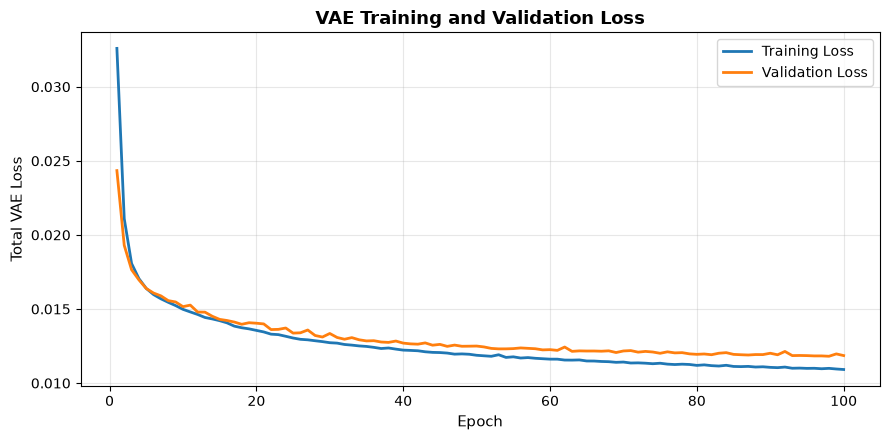

Training curve saved to: C:\DNN\DNN_Project\results\vae_training_curve.png


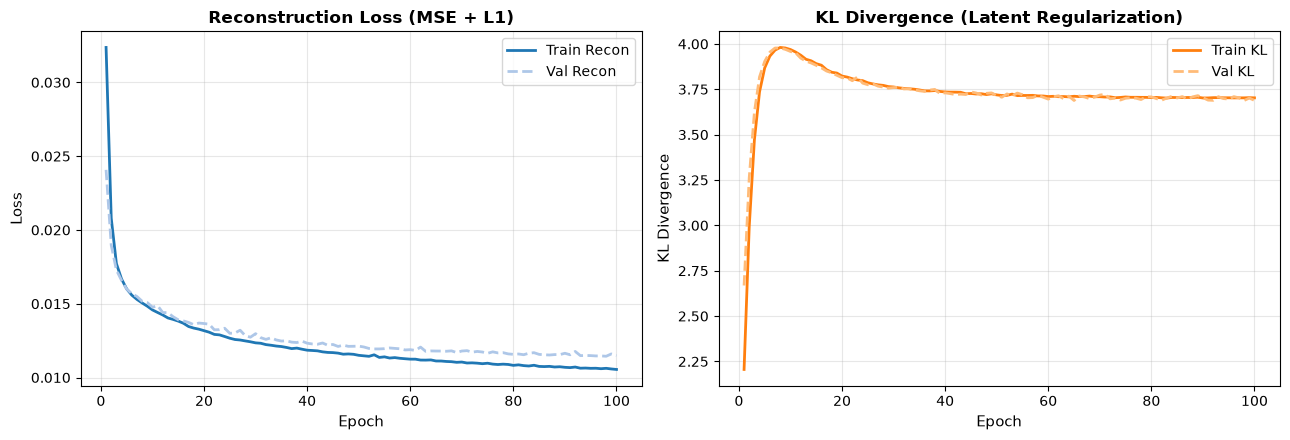

Loss components saved to: C:\DNN\DNN_Project\results\vae_loss_components.png


In [39]:
# Plot Loss Curves
import matplotlib.pyplot as plt
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Total Loss Curve (Train vs Val)
plt.figure(figsize=(9, 4.5))
epochs_range = range(1, len(history["train_loss"]) + 1)
plt.plot(epochs_range, history["train_loss"], label="Training Loss", linewidth=2)
if val_loader is not None:
    plt.plot(epochs_range, history["val_loss"], label="Validation Loss", linewidth=2)
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Total VAE Loss", fontsize=11)
plt.title("VAE Training and Validation Loss", fontsize=13, fontweight="bold")
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
curve_path = RESULTS_DIR / "vae_training_curve.png"
plt.savefig(curve_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Training curve saved to: {curve_path}")

# Loss Components (Reconstruction vs KL Divergence on separate axes)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(epochs_range, history["train_recon"], label="Train Recon", color="#1f77b4", linewidth=2)
if val_loader is not None:
    ax1.plot(epochs_range, history["val_recon"], label="Val Recon", color="#aec7e8", linewidth=2, linestyle="--")
ax1.set_title("Reconstruction Loss (MSE + L1)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Epoch", fontsize=11); ax1.set_ylabel("Loss", fontsize=11)
ax1.grid(True, alpha=0.3); ax1.legend()

ax2.plot(epochs_range, history["train_kl"], label="Train KL", color="#ff7f0e", linewidth=2)
if val_loader is not None:
    ax2.plot(epochs_range, history["val_kl"], label="Val KL", color="#ffbb78", linewidth=2, linestyle="--")
ax2.set_title("KL Divergence (Latent Regularization)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Epoch", fontsize=11); ax2.set_ylabel("KL Divergence", fontsize=11)
ax2.grid(True, alpha=0.3); ax2.legend()

plt.tight_layout()
components_path = RESULTS_DIR / "vae_loss_components.png"
plt.savefig(components_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Loss components saved to: {components_path}")


Targeting checkpoint: vae_best_100ep.pt
SUCCESS: Verified 100-Epoch Checkpoint Loaded: vae_best_100ep.pt
  Trained Epoch: 98 / 100 | Best Val Loss: 0.01181

---------------------------------------------------------------------------
STAGE 1 — 100-EPOCH EVALUATION 
---------------------------------------------------------------------------


,Metric,Value
0,Reconstruction MSE,0.011391
1,Reconstruction MAE,0.071248
2,PSNR (Peak Signal-to-Noise),25.46 dB
3,Latent KL Divergence,3.6886
4,Tokenizer Vocabulary Coverage,100.00%
5,Tokenizer Training UNK Rate,0.00%


Saved 100-epoch metrics to: C:\DNN\DNN_Project\results\evaluation_metrics.json


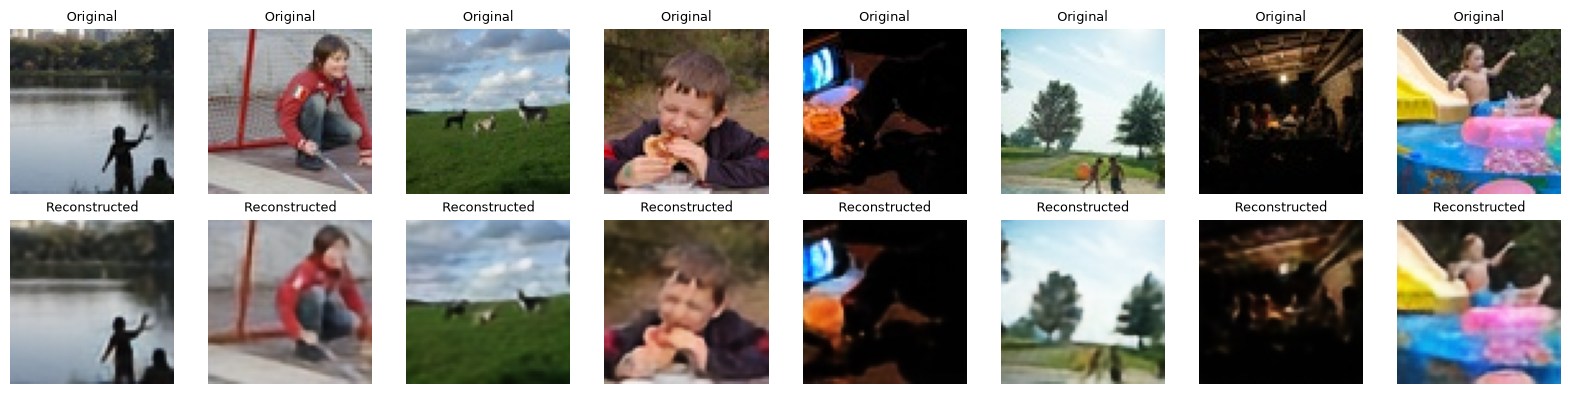

Reconstruction grid saved to: C:\DNN\DNN_Project\results\reconstruction_grid.png


In [ ]:
import re, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch


if 'device' not in globals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if 'vae' not in globals():
    vae = ConvVAE(latent_channels=4).to(device)

best_path_100ep = CHECKPOINT_DIR / "vae_best_100ep.pt"
if not best_path_100ep.exists():
    candidates = sorted(CHECKPOINT_DIR.glob("vae_best_100ep_*.pt"), key=lambda p: p.stat().st_mtime, reverse=True)
    if candidates:
        best_path_100ep = candidates[0]

print(f"Targeting checkpoint: {best_path_100ep.name}")
checkpoint = torch.load(best_path_100ep, map_location=device, weights_only=False)

assert checkpoint["epoch"] >= 60, (
    f" FAILED: Loaded checkpoint is from epoch {checkpoint['epoch']}! "
)

vae.load_state_dict(checkpoint["model_state_dict"])
vae.eval()
print(f"SUCCESS: Verified 100-Epoch Checkpoint Loaded: {best_path_100ep.name}")
print(f"  Trained Epoch: {checkpoint['epoch']} / 100 | Best Val Loss: {checkpoint.get('best_val_loss', 'N/A'):.5f}")

# ---------------------------------------------------------------------------
# Compute Metrics (MSE, MAE, PSNR, KL) across Validation Split
# ---------------------------------------------------------------------------
eval_loader = val_loader if val_loader is not None else train_loader
mse_sum = 0.0
mae_sum = 0.0
kl_sum = 0.0
pixel_count = 0
sample_count = 0

with torch.no_grad():
    for batch in eval_loader:
        images = batch[0] if isinstance(batch, (tuple, list)) else batch
        images = images.to(device)
        
        # Deterministic reconstruction using posterior mean mu
        mu, logvar = vae.encode(images)
        reconstruction = vae.decode(mu)
        
        diff = reconstruction.float() - images.float()
        
        # Mean Squared Error (MSE)
        mse_sum += diff.square().sum().item()
        
        # Mean Absolute Error (MAE)
        mae_sum += diff.abs().sum().item()
        pixel_count += images.numel()
        
        # KL Divergence (normalized per latent dimension: 4 x 16 x 16 = 1024)
        kl_per_sample = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).flatten(1).sum(1)
        latent_dims = mu.shape[1] * mu.shape[2] * mu.shape[3]
        kl_loss = kl_per_sample / latent_dims
        kl_sum += kl_loss.sum().item()
        sample_count += images.size(0)

mse = mse_sum / pixel_count
mae = mae_sum / pixel_count

# Peak Signal-to-Noise Ratio (PSNR)
psnr = float("inf") if mse == 0 else 10.0 * np.log10(4.0 / mse)

#  Average Latent KL Divergence per dimension
mean_kl = kl_sum / sample_count

# ---------------------------------------------------------------------------
# Tokenizer Vocabulary Coverage & UNK Rate
# ---------------------------------------------------------------------------
with open(TOKENIZER_DIR / "vocab.json", "r", encoding="utf-8") as f:
    vocab = json.load(f)

def tokenize_text(text):
    return re.findall(r"[a-z0-9]+(?:'[a-z]+)?", str(text).lower())

train_csv = DATA_DIR / "train" / "captions.csv"
train_df = pd.read_csv(train_csv)
total_tokens = 0
unk_tokens = 0
for packed in train_df["captions"]:
    caption_list = json.loads(packed) if isinstance(packed, str) else [str(packed)]
    for caption in caption_list:
        for token in tokenize_text(caption):
            total_tokens += 1
            if token not in vocab:
                unk_tokens += 1

unk_rate = (100.0 * unk_tokens / total_tokens) if total_tokens else 0.0
vocab_coverage = 100.0 - unk_rate


scorecard_df = pd.DataFrame([
    {"Metric": "Reconstruction MSE", "Value": f"{mse:.6f}"},
    {"Metric": "Reconstruction MAE", "Value": f"{mae:.6f}"},
    {"Metric": "PSNR (Peak Signal-to-Noise)", "Value": f"{psnr:.2f} dB"},
    {"Metric": "Latent KL Divergence", "Value": f"{mean_kl:.4f}", },
    {"Metric": "Tokenizer Vocabulary Coverage", "Value": f"{vocab_coverage:.2f}%"},
    {"Metric": "Tokenizer Training UNK Rate", "Value": f"{unk_rate:.2f}%"}
])

print("\n" + "-"*75)
print("STAGE 1 — 100-EPOCH EVALUATION ")
print("-"*75)
display(scorecard_df)

# Export metrics to dedicated 100-epoch JSON
metrics_export = {
    "experiment": "100_epochs",
    "reconstruction_mse": round(mse, 6),
    "reconstruction_mae": round(mae, 6),
    "psnr_db": round(psnr, 2),
    "latent_kl_divergence": round(mean_kl, 4),
    "tokenizer_vocab_coverage_percent": round(vocab_coverage, 2),
    "tokenizer_unk_rate_percent": round(unk_rate, 4),
    "vocabulary_size": len(vocab),
    "checkpoint": str(best_path_100ep),
    "checkpoint_epoch": checkpoint["epoch"],
    "best_val_loss": checkpoint.get("best_val_loss")
}
with open(RESULTS_DIR / "evaluation_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics_export, f, indent=2)
print(f"Saved 100-epoch metrics to: {RESULTS_DIR / 'evaluation_metrics.json'}")


batch = next(iter(eval_loader))
images = batch[0] if isinstance(batch, (tuple, list)) else batch
images = images.to(device)

with torch.no_grad():
    mu, _ = vae.encode(images)
    reconstructions = vae.decode(mu)

# Convert [-1, 1] back to [0, 1] for display
originals = ((images[:8].cpu() + 1.0) / 2.0).clamp(0, 1)
recons = ((reconstructions[:8].cpu() + 1.0) / 2.0).clamp(0, 1)

n = min(8, len(originals))
fig, axes = plt.subplots(2, n, figsize=(2 * n, 4))
for i in range(n):
    axes[0, i].imshow(originals[i].permute(1, 2, 0))
    axes[0, i].set_title("Original", fontsize=9); axes[0, i].axis("off")
    axes[1, i].imshow(recons[i].permute(1, 2, 0))
    axes[1, i].set_title("Reconstructed", fontsize=9); axes[1, i].axis("off")

plt.tight_layout()
grid_path = RESULTS_DIR / "reconstruction_grid.png"
plt.savefig(grid_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Reconstruction grid saved to: {grid_path}")

### Encode & Cache Latents for Member 2 

In [ ]:
# Always ensure the best validation checkpoint is restored before caching
if 'best_path' not in globals() or not Path(best_path).exists():
    best_path = CHECKPOINT_DIR / "vae_best.pt"
if 'device' not in globals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if 'vae' not in globals():
    vae = ConvVAE(latent_channels=4).to(device)

checkpoint = torch.load(best_path, map_location=device, weights_only=False)
vae.load_state_dict(checkpoint["model_state_dict"])
vae.eval()

print("Restored best checkpoint for caching:", best_path.name)
print(f"Checkpoint Epoch: {checkpoint['epoch']} | Best Val Loss: {checkpoint.get('best_val_loss', 'N/A')}")

@torch.no_grad()
def cache_latents(split):
    dataset = FlickrImageDataset(split, image_transform)
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
    out_dir = LATENT_DIR / split
    out_dir.mkdir(parents=True, exist_ok=True)
    output_path = out_dir / "latents.pt"

    latent_batches, token_batches, image_ids, captions = [], [], [], []
    
    for images, batch_captions, batch_ids in tqdm(loader, desc=f"Caching {split} latents"):
        images = images.to(device, non_blocking=True)
        # Deterministic latent representation 
        mu, _ = vae.encode(images)
        latent_batches.append(mu.cpu().to(torch.float16))
        
        # Pre-tokenize captions into token IDs
        tokens = torch.tensor([encode_caption(c) for c in batch_captions], dtype=torch.long)
        token_batches.append(tokens)
        
        image_ids.extend(list(batch_ids))
        captions.extend(list(batch_captions))

    latents = torch.cat(latent_batches, dim=0)
    token_ids = torch.cat(token_batches, dim=0)
    
    cache_dict = {
        "latents": latents,                    # Shape: [N, 4, 16, 16]
        "token_ids": token_ids,                # Shape: [N, 40]
        "image_ids": image_ids,
        "captions": captions,
        "latent_dtype": str(latents.dtype),
        "latent_channels": LATENT_CHANNELS,
        "image_size": IMAGE_SIZE,
        "checkpoint": str(best_path),
        "checkpoint_epoch": checkpoint["epoch"],
        "checkpoint_val_loss": checkpoint.get("best_val_loss", checkpoint.get("best_loss")),
        "source_split": split
    }
    torch.save(cache_dict, output_path)
    
    pd.DataFrame({"image_id": image_ids, "caption": captions}).to_csv(
        out_dir / "latent_index.csv", index=False
    )
    print(f"\n{split} cache saved to: {output_path}")
    print(f"  Latents: {tuple(latents.shape)}, dtype: {latents.dtype}")
    print(f"  Token IDs: {tuple(token_ids.shape)}, dtype: {token_ids.dtype}")

cache_latents("train")
if (DATA_DIR / "val" / "captions.csv").exists():
    cache_latents("val")

Restored best checkpoint for caching: vae_best_100ep_20261028_195853.pt
Checkpoint Epoch: 98 | Best Val Loss: 0.01181043717265129


Caching train latents:   0%|          | 0/375 [00:00<?, ?it/s]


train cache saved to: C:\DNN\DNN_Project\latents\train\latents.pt
  Latents: (6000, 4, 16, 16), dtype: torch.float16
  Token IDs: (6000, 40), dtype: torch.int64


Caching val latents:   0%|          | 0/63 [00:00<?, ?it/s]


val cache saved to: C:\DNN\DNN_Project\latents\val\latents.pt
  Latents: (1000, 4, 16, 16), dtype: torch.float16
  Token IDs: (1000, 40), dtype: torch.int64


In [42]:
def verify_latent_cache(split, expected_count):
    path = LATENT_DIR / split / "latents.pt"

    assert path.exists(), f"Missing cache: {path}"

    cache = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    latents = cache["latents"]
    token_ids = cache["token_ids"]

    assert latents.shape == (
        expected_count,
        LATENT_CHANNELS,
        16,
        16
    ), f"Unexpected latent shape: {tuple(latents.shape)}"

    assert token_ids.shape == (
        expected_count,
        MAX_TEXT_LENGTH
    ), f"Unexpected token shape: {tuple(token_ids.shape)}"

    assert len(cache["captions"]) == expected_count
    assert len(cache["image_ids"]) == expected_count
    assert torch.isfinite(latents.float()).all(), "Latents contain NaN/Inf"

    print(f"\n{split}: cache verification passed")
    print("Latents:", tuple(latents.shape), latents.dtype)
    print("Tokens:", tuple(token_ids.shape), token_ids.dtype)
    print("Checkpoint:", cache["checkpoint"])

verify_latent_cache("train", 6000)
verify_latent_cache("val", 1000)


train: cache verification passed
Latents: (6000, 4, 16, 16) torch.float16
Tokens: (6000, 40) torch.int64
Checkpoint: C:\DNN\DNN_Project\checkpoints\vae_best_100ep_20261028_195853.pt

val: cache verification passed
Latents: (1000, 4, 16, 16) torch.float16
Tokens: (1000, 40) torch.int64
Checkpoint: C:\DNN\DNN_Project\checkpoints\vae_best_100ep_20261028_195853.pt


### Export `models/vae.py` & Verify Member 1 Handover Checklist

In [ ]:
# Export Python Modules and Deliverables Verification
vae_module_code = '''import torch
import torch.nn as nn

class ConvVAE(nn.Module):
    def __init__(self, latent_channels=4):
        super().__init__()
        self.latent_channels = latent_channels
        
        # Encoder: (3, 64, 64) -> (256, 16, 16)
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1), nn.GroupNorm(8, 64), nn.SiLU(),
            nn.Conv2d(64, 128, 4, 2, 1), nn.GroupNorm(8, 128), nn.SiLU(),
            nn.Conv2d(128, 256, 3, 1, 1), nn.GroupNorm(8, 256), nn.SiLU(),
        )
        self.to_mu = nn.Conv2d(256, latent_channels, 1)
        self.to_logvar = nn.Conv2d(256, latent_channels, 1)

        # Decoder: (4, 16, 16) -> (3, 64, 64)
        self.decoder_input = nn.Sequential(
            nn.Conv2d(latent_channels, 256, 3, 1, 1),
            nn.GroupNorm(8, 256), nn.SiLU(),
        )
        self.decoder = nn.Sequential(
            nn.Conv2d(256, 128, 3, 1, 1), nn.GroupNorm(8, 128), nn.SiLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.GroupNorm(8, 64), nn.SiLU(),
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.GroupNorm(8, 32), nn.SiLU(),
            nn.Conv2d(32, 3, 3, 1, 1), nn.Tanh(),
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.to_mu(h)
        logvar = self.to_logvar(h).clamp(-10, 10)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(self.decoder_input(z))

    def forward(self, x, sample=True):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar) if sample else mu
        return self.decode(z), mu, logvar
'''

tokenizer_module_code = '''import json
import re
from pathlib import Path

class SimpleTokenizer:
    """
    Word-level tokenizer matching the vocabulary and preprocessing 
    defined in Stage 1 of the DNN Assignment.
    """
    def __init__(self, vocab=None, max_length=40):
        self.vocab = vocab or {}
        self.id_to_vocab = {idx: token for token, idx in self.vocab.items()}
        self.max_length = max_length
        self.pad_id = self.vocab.get("<pad>", 0)
        self.unk_id = self.vocab.get("<unk>", 1)
        self.bos_id = self.vocab.get("<bos>", 2)
        self.eos_id = self.vocab.get("<eos>", 3)

    @classmethod
    def load(cls, tokenizer_dir=None):
        if tokenizer_dir is None:
            tokenizer_dir = Path(__file__).resolve().parent
        else:
            tokenizer_dir = Path(tokenizer_dir)
        
        vocab_path = tokenizer_dir / "vocab.json"
        config_path = tokenizer_dir / "tokenizer_config.json"
        
        with open(vocab_path, "r", encoding="utf-8") as f:
            vocab = json.load(f)
            
        max_length = 40
        if config_path.exists():
            with open(config_path, "r", encoding="utf-8") as f:
                cfg = json.load(f)
                max_length = cfg.get("max_text_length", 40)
                
        return cls(vocab=vocab, max_length=max_length)

    def tokenize_text(self, text):
        return re.findall(r"[a-z0-9]+(?:'[a-z]+)?", str(text).lower())

    def encode(self, text, max_length=None):
        if max_length is None:
            max_length = self.max_length
        tokens = self.tokenize_text(text)
        ids = [self.bos_id] + [self.vocab.get(t, self.unk_id) for t in tokens[:max_length-2]] + [self.eos_id]
        ids = ids[:max_length]
        return ids + [self.pad_id] * (max_length - len(ids))

    def decode(self, token_ids):
        tokens = [self.id_to_vocab.get(int(i), "<unk>") for i in token_ids]
        return " ".join([t for t in tokens if t not in ["<pad>", "<bos>", "<eos>"]])
'''

with open(MODEL_DIR / "vae.py", "w", encoding="utf-8") as f:
    f.write(vae_module_code)
(MODEL_DIR / "__init__.py").touch(exist_ok=True)

with open(TOKENIZER_DIR / "tokenizer.py", "w", encoding="utf-8") as f:
    f.write(tokenizer_module_code)
(TOKENIZER_DIR / "__init__.py").touch(exist_ok=True)

print("Saved models/vae.py and tokenizer/tokenizer.py for Member 2 handover!")

# Final Deliverables Verification against actual best_path, evaluation metrics, and latents
deliverables = [
    TOKENIZER_DIR / "vocab.json",
    TOKENIZER_DIR / "tokenizer_config.json",
    TOKENIZER_DIR / "tokenizer.py",
    MODEL_DIR / "vae.py",
    best_path,
    RESULTS_DIR / "evaluation_metrics.json",
    RESULTS_DIR / "reconstruction_grid.png",
    RESULTS_DIR / "vae_training_curve.png",
    RESULTS_DIR / "vae_loss_components.png",
    LATENT_DIR / "train" / "latents.pt",
    LATENT_DIR / "val" / "latents.pt",
]

print("\n--- FINAL DELIVERABLE CHECK ---")
all_ready = True
for path in deliverables:
    exists = path.exists()
    status = "READY" if exists else "MISSING"
    print(f"[{status:7s}] {path.name}")
    if not exists:
        all_ready = False

print("\nAll deliverables are ready for Member 2!" if all_ready else "\nSome deliverables are missing. Check the paths above.")


Saved models/vae.py and tokenizer/tokenizer.py for Member 2 handover!

--- FINAL DELIVERABLE CHECK ---
[READY  ] vocab.json
[READY  ] tokenizer_config.json
[READY  ] tokenizer.py
[READY  ] vae.py
[READY  ] vae_best_100ep_20261028_195853.pt
[READY  ] evaluation_metrics.json
[READY  ] reconstruction_grid.png
[READY  ] vae_training_curve.png
[READY  ] vae_loss_components.png
[READY  ] latents.pt
[READY  ] latents.pt

All deliverables are ready for Member 2!
